
# Partie 1 — AdaBoost sur MNIST

**Objectif :** étudier l'effet du classifieur faible, du nombre d'étapes de boosting et de la tâche de classification binaire sur les performances d'AdaBoost.

Le jeu de données MNIST contient des images de chiffres manuscrits de taille \(28 * 28\), soit **784 pixels par image**. Nous utilisons directement ces 784 variables, **sans ACP ni autre réduction de dimension**.

## Plan
1. Charger MNIST et préparer les deux tâches binaires.
2. Définir les classifieurs faibles.
3. Entraîner AdaBoost pour chaque combinaison.
4. Calculer et conserver les matrices de confusion.
5. Comparer les performances et discuter les résultats.

Les valeurs de profondeur et le nombre d'estimateurs ci-dessous constituent notre protocole expérimental : l'énoncé demande de les faire varier, sans imposer de valeurs précises.



## 1. Imports et configuration

Nous utilisons `scikit-learn` pour les modèles et les métriques, `pandas` pour organiser les résultats et `matplotlib` pour les visualisations.


In [1]:

from pathlib import Path
import inspect
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

# Dossiers de sortie, créés à partir de la racine du projet
PROJECT_ROOT = Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = RESULTS_DIR / "models"
MATRICES_DIR = RESULTS_DIR / "confusion_matrices"

for directory in (RESULTS_DIR, MODELS_DIR, MATRICES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Répertoire du projet :", PROJECT_ROOT.resolve())
print("Dossiers de résultats prêts.")


Répertoire du projet : /mnt/c/Users/gleis/Downloads
Dossiers de résultats prêts.



## 2. Chargement de MNIST

Nous chargeons la version `mnist_784` disponible via OpenML. Elle contient les 70 000 images dans l'ordre du découpage officiel : les 60 000 premières pour l'apprentissage et les 10 000 dernières pour le test.

Chaque pixel est initialement codé entre 0 et 255. Nous ramenons les valeurs dans `[0, 1]` en divisant par 255. Cette transformation conserve les 784 variables : ce n'est pas une réduction de dimension.

**Remarque :** le premier chargement nécessite une connexion Internet et peut prendre un peu de temps.


In [2]:

# Compatibilité avec plusieurs versions de scikit-learn
try:
    mnist = fetch_openml(
        name="mnist_784",
        version=1,
        as_frame=False,
        parser="auto"
    )
except TypeError:
    # Anciennes versions de scikit-learn sans l'argument parser
    mnist = fetch_openml(
        name="mnist_784",
        version=1,
        as_frame=False
    )

X_all = mnist.data.astype(np.float32) / 255.0
y_all = mnist.target.astype(str)

# Découpage officiel MNIST
X_train_all = X_all[:60000]
y_train_all = y_all[:60000]

X_test_all = X_all[60000:]
y_test_all = y_all[60000:]

print("X_train :", X_train_all.shape)
print("X_test  :", X_test_all.shape)
print("Nombre de pixels par image :", X_train_all.shape[1])
print("Valeurs des pixels :", X_train_all.min(), "à", X_train_all.max())


X_train : (60000, 784)
X_test  : (10000, 784)
Nombre de pixels par image : 784
Valeurs des pixels : 0.0 à 1.0



### Visualisation de quelques images

Avant l'apprentissage, vérifions que les images ont bien été chargées et que leur représentation 28 × 28 est correcte.


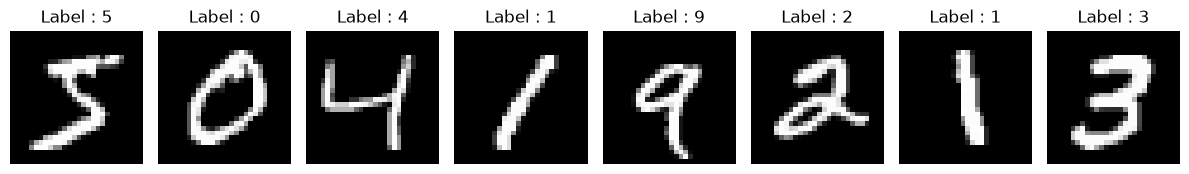

In [3]:

fig, axes = plt.subplots(1, 8, figsize=(12, 2))

for i, ax in enumerate(axes):
    ax.imshow(X_train_all[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label : {y_train_all[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()



## 3. Préparation des tâches de classification binaire

Nous étudions deux problèmes :

- **3 contre 8 :** classe 0 = chiffre 3 ; classe 1 = chiffre 8.
- **0–4 contre 5–9 :** classe 0 = chiffres de 0 à 4 ; classe 1 = chiffres de 5 à 9.

Dans les deux cas, la classe positive (label 1) correspond au second groupe cité. Nous conservons le découpage train/test officiel de MNIST.


In [4]:

def prepare_binary_task(X_train, y_train, X_test, y_test, task_name):
    """Construit X_train, y_train, X_test, y_test pour une tâche binaire."""

    y_train_int = y_train.astype(int)
    y_test_int = y_test.astype(int)

    if task_name == "3_vs_8":
        train_mask = np.isin(y_train_int, [3, 8])
        test_mask = np.isin(y_test_int, [3, 8])

        X_train_task = X_train[train_mask]
        X_test_task = X_test[test_mask]

        # 3 -> 0 ; 8 -> 1
        y_train_task = (y_train_int[train_mask] == 8).astype(int)
        y_test_task = (y_test_int[test_mask] == 8).astype(int)

        class_names = ["3", "8"]

    elif task_name == "0_4_vs_5_9":
        # Tous les exemples sont conservés
        X_train_task = X_train
        X_test_task = X_test

        # 0 à 4 -> 0 ; 5 à 9 -> 1
        y_train_task = (y_train_int >= 5).astype(int)
        y_test_task = (y_test_int >= 5).astype(int)

        class_names = ["0–4", "5–9"]

    else:
        raise ValueError(f"Tâche inconnue : {task_name}")

    return (
        X_train_task,
        y_train_task,
        X_test_task,
        y_test_task,
        class_names
    )


TASKS = {
    "3_vs_8": "3 contre 8",
    "0_4_vs_5_9": "0–4 contre 5–9",
}

datasets = {}

for task_key in TASKS:
    datasets[task_key] = prepare_binary_task(
        X_train_all, y_train_all,
        X_test_all, y_test_all,
        task_key
    )

    Xtr, ytr, Xte, yte, names = datasets[task_key]

    print(f"\nTâche : {TASKS[task_key]}")
    print("Train :", Xtr.shape, "| Test :", Xte.shape)
    print("Répartition train :", np.bincount(ytr))
    print("Répartition test  :", np.bincount(yte))



Tâche : 3 contre 8
Train : (11982, 784) | Test : (1984, 784)
Répartition train : [6131 5851]
Répartition test  : [1010  974]

Tâche : 0–4 contre 5–9
Train : (60000, 784) | Test : (10000, 784)
Répartition train : [30596 29404]
Répartition test  : [5139 4861]



## 4. Définition des classifieurs faibles et des paramètres

Nous comparons quatre classifieurs faibles :

1. **Decision stump :** arbre de décision de profondeur 1. Dans l'espace des pixels, il effectue une décision à partir d'un pixel.
2. **Perceptron :** classifieur linéaire.
3. **Arbre de profondeur 3.**
4. **Arbre de profondeur 8.**

Nous testons trois nombres d'estimateurs AdaBoost : **10, 50 et 200**.

Le perceptron et les arbres sont utilisés comme estimateurs de base. AdaBoost doit pouvoir leur transmettre les poids des observations (`sample_weight`), ce que nous vérifierons avant de lancer les expériences.


In [5]:

N_ESTIMATORS_LIST = [10, 50, 200]

def make_weak_learners():
    return {
        "Decision stump (depth=1)": DecisionTreeClassifier(
            max_depth=1,
            random_state=RANDOM_STATE
        ),
        "Perceptron": Perceptron(
            max_iter=1000,
            tol=1e-3,
            random_state=RANDOM_STATE
        ),
        "Decision tree (depth=3)": DecisionTreeClassifier(
            max_depth=3,
            random_state=RANDOM_STATE
        ),
        "Decision tree (depth=8)": DecisionTreeClassifier(
            max_depth=8,
            random_state=RANDOM_STATE
        ),
    }


# Vérification de la présence du paramètre sample_weight
for name, learner in make_weak_learners().items():
    supports_sample_weight = (
        "sample_weight" in inspect.signature(learner.fit).parameters
    )
    print(f"{name}: sample_weight supporté = {supports_sample_weight}")


Decision stump (depth=1): sample_weight supporté = True
Perceptron: sample_weight supporté = True
Decision tree (depth=3): sample_weight supporté = True
Decision tree (depth=8): sample_weight supporté = True



## 5. Entraînement et évaluation

Pour chaque combinaison (tâche, classifieur faible, nombre d'estimateurs), nous :

- entraînons un modèle AdaBoost ;
- prédisons les classes sur le jeu de test ;
- calculons la matrice de confusion ;
- calculons l'accuracy, la précision, le rappel et le F1-score ;
- sauvegardons la matrice de confusion sous forme de fichier CSV.

La convention des matrices est la suivante : **lignes = vraies classes** et **colonnes = classes prédites**. L'ordre des classes est toujours `[0, 1]`.


In [6]:

def build_adaboost(weak_learner, n_estimators):
    """Construit AdaBoost en tenant compte du nom du paramètre sklearn."""
    parameters = inspect.signature(AdaBoostClassifier).parameters

    common_params = {
        "n_estimators": n_estimators,
        "random_state": RANDOM_STATE,
    }

    if "estimator" in parameters:
        return AdaBoostClassifier(estimator=weak_learner, **common_params)

    # Compatibilité avec les anciennes versions de scikit-learn
    return AdaBoostClassifier(base_estimator=weak_learner, **common_params)


results = []
trained_stump_models = {}

for task_key, task_label in TASKS.items():
    Xtr, ytr, Xte, yte, class_names = datasets[task_key]

    for learner_name, learner_template in make_weak_learners().items():
        for n_estimators in N_ESTIMATORS_LIST:

            print(
                f"\nTraining: task={task_key} | "
                f"learner={learner_name} | "
                f"n_estimators={n_estimators}"
            )

            model = build_adaboost(
                weak_learner=learner_template,
                n_estimators=n_estimators
            )

            start_time = time.time()

            try:
                model.fit(Xtr, ytr)
                y_pred = model.predict(Xte)
                elapsed = time.time() - start_time

                cm = confusion_matrix(yte, y_pred, labels=[0, 1])

                accuracy = accuracy_score(yte, y_pred)
                precision = precision_score(
                    yte, y_pred, zero_division=0
                )
                recall = recall_score(
                    yte, y_pred, zero_division=0
                )
                f1 = f1_score(
                    yte, y_pred, zero_division=0
                )

                row = {
                    "task": task_key,
                    "task_label": task_label,
                    "weak_learner": learner_name,
                    "n_estimators_requested": n_estimators,
                    "n_estimators_fitted": len(model.estimators_),
                    "accuracy": accuracy,
                    "precision": precision,
                    "recall": recall,
                    "f1_score": f1,
                    "training_time_seconds": elapsed,
                    "status": "success",
                }

                # Une matrice par combinaison expérimentale
                matrix_filename = (
                    f"cm_{task_key}_"
                    f"{learner_name.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('=', '')}_"
                    f"{n_estimators}.csv"
                )
                pd.DataFrame(
                    cm,
                    index=[f"true_{class_names[0]}", f"true_{class_names[1]}"],
                    columns=[f"pred_{class_names[0]}", f"pred_{class_names[1]}"]
                ).to_csv(MATRICES_DIR / matrix_filename)

                # Garder les modèles de stumps pour la partie 2
                if learner_name == "Decision stump (depth=1)":
                    model_filename = f"adaboost_stump_{task_key}_{n_estimators}.joblib"
                    import joblib
                    joblib.dump(model, MODELS_DIR / model_filename)
                    trained_stump_models[(task_key, n_estimators)] = model

                results.append(row)

                print("Matrice de confusion :")
                print(cm)
                print(f"Accuracy : {accuracy:.4f} | F1 : {f1:.4f}")
                print(f"Estimateurs effectivement entraînés : {len(model.estimators_)}")
                print(f"Temps : {elapsed:.1f} s")

            except Exception as error:
                # On conserve l'erreur dans le tableau pour ne pas perdre
                # les autres expériences si une configuration échoue.
                print("ÉCHEC :", repr(error))
                results.append({
                    "task": task_key,
                    "task_label": task_label,
                    "weak_learner": learner_name,
                    "n_estimators_requested": n_estimators,
                    "n_estimators_fitted": np.nan,
                    "accuracy": np.nan,
                    "precision": np.nan,
                    "recall": np.nan,
                    "f1_score": np.nan,
                    "training_time_seconds": np.nan,
                    "status": f"failed: {type(error).__name__}: {error}",
                })

results_df = pd.DataFrame(results)
results_df.to_csv(RESULTS_DIR / "adaboost_results.csv", index=False)

print("\nExpériences terminées.")
print("Nombre de configurations :", len(results_df))
print("Résultats sauvegardés dans :", RESULTS_DIR.resolve())



Training: task=3_vs_8 | learner=Decision stump (depth=1) | n_estimators=10
Matrice de confusion :
[[917  93]
 [ 84 890]]
Accuracy : 0.9108 | F1 : 0.9096
Estimateurs effectivement entraînés : 10
Temps : 2.1 s

Training: task=3_vs_8 | learner=Decision stump (depth=1) | n_estimators=50
Matrice de confusion :
[[962  48]
 [ 52 922]]
Accuracy : 0.9496 | F1 : 0.9486
Estimateurs effectivement entraînés : 50
Temps : 9.2 s

Training: task=3_vs_8 | learner=Decision stump (depth=1) | n_estimators=200
Matrice de confusion :
[[971  39]
 [ 35 939]]
Accuracy : 0.9627 | F1 : 0.9621
Estimateurs effectivement entraînés : 200
Temps : 39.0 s

Training: task=3_vs_8 | learner=Perceptron | n_estimators=10
Matrice de confusion :
[[972  38]
 [ 34 940]]
Accuracy : 0.9637 | F1 : 0.9631
Estimateurs effectivement entraînés : 10
Temps : 2.0 s

Training: task=3_vs_8 | learner=Perceptron | n_estimators=50
Matrice de confusion :
[[971  39]
 [ 27 947]]
Accuracy : 0.9667 | F1 : 0.9663
Estimateurs effectivement entraînés


## 6. Comparaison des performances

Nous présentons les performances de toutes les configurations. L'accuracy donne la proportion totale de prédictions correctes ; le F1-score combine précision et rappel. Il faut lire ces indicateurs avec les matrices de confusion, notamment lorsque les classes ne sont pas équilibrées.


In [7]:

# Tableau récapitulatif trié par tâche et F1-score
display(
    results_df.sort_values(
        ["task", "f1_score"],
        ascending=[True, False]
    ).reset_index(drop=True)
)


,task,task_label,weak_learner,n_estimators_requested,n_estimators_fitted,accuracy,precision,recall,f1_score,training_time_seconds,status
0,0_4_vs_5_9,0–4 contre 5–9,Decision tree (depth=8),200,200,0.982200,0.980308,0.983131,0.981717,1145.414640,success
1,0_4_vs_5_9,0–4 contre 5–9,Decision tree (depth=8),50,50,0.972700,0.971628,0.972228,0.971928,294.360037,success
2,0_4_vs_5_9,0–4 contre 5–9,Decision tree (depth=3),200,200,0.956400,0.956845,0.953302,0.955070,380.964470,success
3,0_4_vs_5_9,0–4 contre 5–9,Decision tree (depth=8),10,10,0.949000,0.946440,0.948776,0.947606,57.222875,success
4,0_4_vs_5_9,0–4 contre 5–9,Decision tree (depth=3),50,50,0.923600,0.920723,0.922238,0.921480,97.466719,success
5,0_4_vs_5_9,0–4 contre 5–9,Decision tree (depth=3),10,10,0.835100,0.830317,0.830488,0.830402,19.072390,success
6,0_4_vs_5_9,0–4 contre 5–9,Decision stump (depth=1),200,200,0.833500,0.826923,0.831516,0.829213,128.888261,success
7,0_4_vs_5_9,0–4 contre 5–9,Decision stump (depth=1),50,50,0.807100,0.795803,0.811356,0.803504,31.339079,success
8,0_4_vs_5_9,0–4 contre 5–9,Perceptron,10,6,0.814500,0.845835,0.756223,0.798523,4.036678,success
9,0_4_vs_5_9,0–4 contre 5–9,Perceptron,50,6,0.814500,0.845835,0.756223,0.798523,3.731626,success


In [8]:

# Meilleure et moins bonne configuration de chaque tâche
successful = results_df[results_df["status"] == "success"].copy()

for task_key, task_label in TASKS.items():
    subset = successful[successful["task"] == task_key]

    print(f"\n===== {task_label} =====")

    if subset.empty:
        print("Aucune configuration n'a réussi pour cette tâche.")
        continue

    best = subset.loc[subset["f1_score"].idxmax()]
    worst = subset.loc[subset["f1_score"].idxmin()]

    print("Meilleure configuration (F1) :")
    display(best.to_frame().T)

    print("Moins bonne configuration (F1) :")
    display(worst.to_frame().T)



===== 3 contre 8 =====
Meilleure configuration (F1) :


,task,task_label,weak_learner,n_estimators_requested,n_estimators_fitted,accuracy,precision,recall,f1_score,training_time_seconds,status
8,3_vs_8,3 contre 8,Decision tree (depth=3),200,200,0.99496,0.992843,0.99692,0.994877,103.139808,success


Moins bonne configuration (F1) :


,task,task_label,weak_learner,n_estimators_requested,n_estimators_fitted,accuracy,precision,recall,f1_score,training_time_seconds,status
0,3_vs_8,3 contre 8,Decision stump (depth=1),10,10,0.910786,0.905392,0.913758,0.909555,2.065358,success



===== 0–4 contre 5–9 =====
Meilleure configuration (F1) :


,task,task_label,weak_learner,n_estimators_requested,n_estimators_fitted,accuracy,precision,recall,f1_score,training_time_seconds,status
23,0_4_vs_5_9,0–4 contre 5–9,Decision tree (depth=8),200,200,0.9822,0.980308,0.983131,0.981717,1145.41464,success


Moins bonne configuration (F1) :


,task,task_label,weak_learner,n_estimators_requested,n_estimators_fitted,accuracy,precision,recall,f1_score,training_time_seconds,status
12,0_4_vs_5_9,0–4 contre 5–9,Decision stump (depth=1),10,10,0.7671,0.734444,0.815882,0.773024,6.247609,success



## 7. Visualisation des matrices de confusion

Les matrices ont déjà été enregistrées individuellement dans `results/confusion_matrices/`. Nous pouvons également afficher les matrices des expériences réussies dans le notebook.


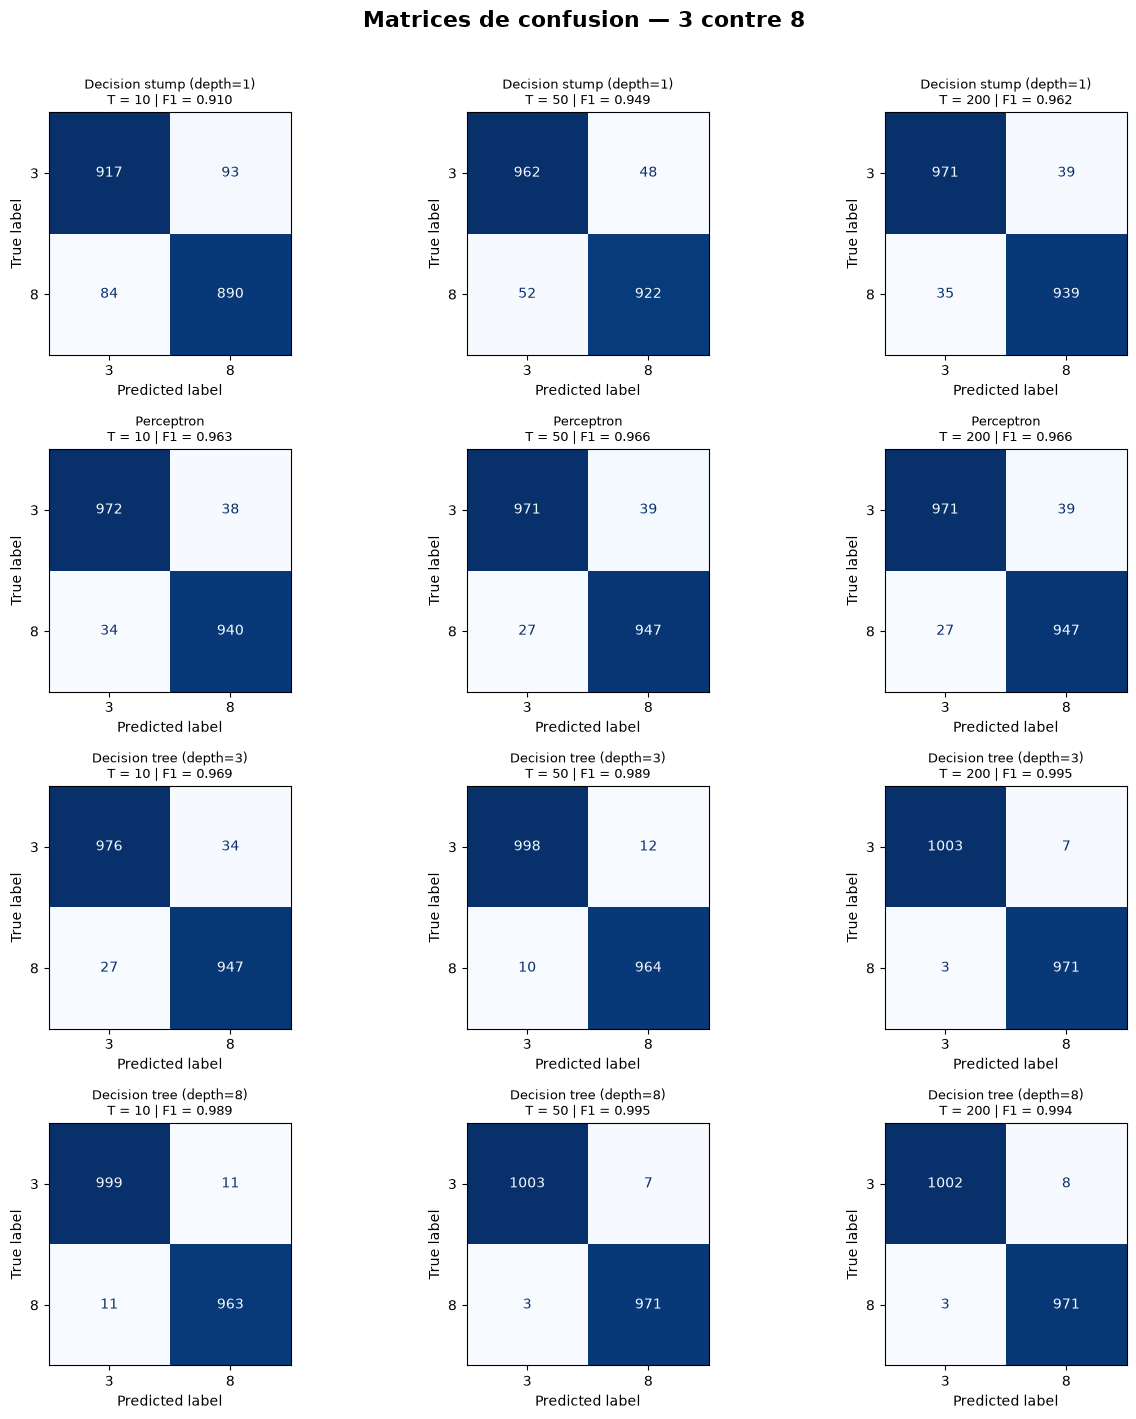

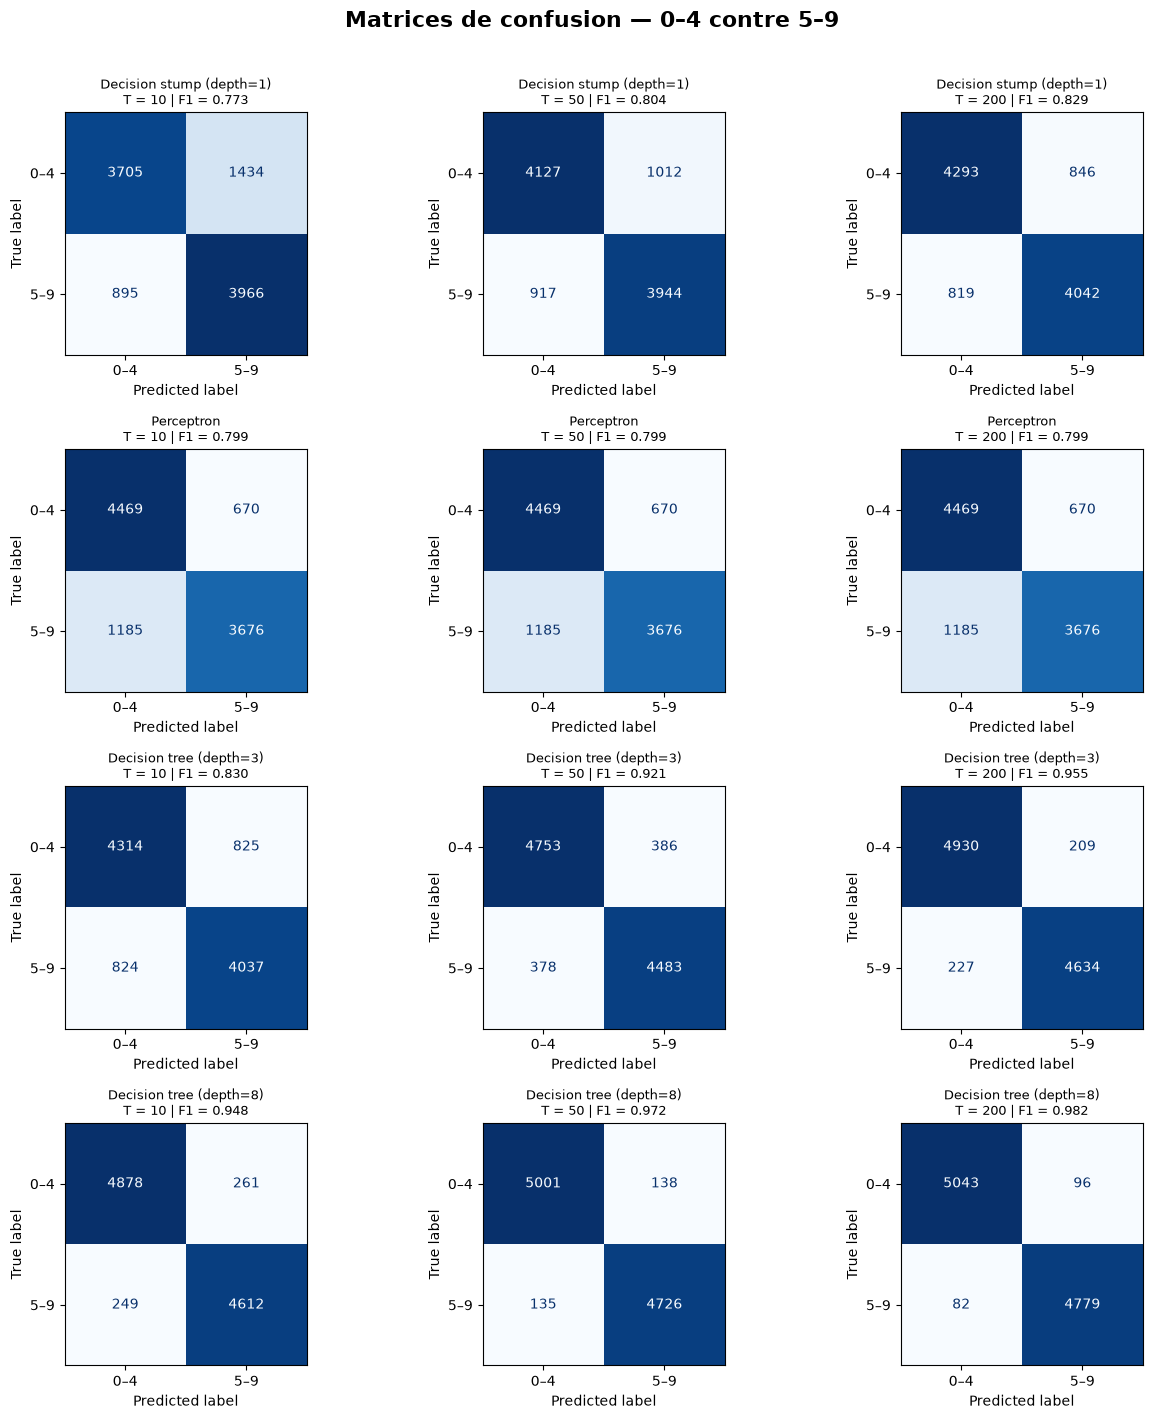

In [10]:

# Afficher les matrices de confusion sous forme de grilles 4 x 3

learner_names = list(make_weak_learners().keys())

for task_key, task_label in TASKS.items():

    Xtr, ytr, Xte, yte, class_names = datasets[task_key]

    fig, axes = plt.subplots(
        nrows=4,
        ncols=3,
        figsize=(13, 14)
    )

    fig.suptitle(
        f"Matrices de confusion — {task_label}",
        fontsize=16,
        fontweight="bold",
        y=1.01
    )

    for i, learner_name in enumerate(learner_names):

        for j, n_estimators in enumerate(N_ESTIMATORS_LIST):

            ax = axes[i, j]

            matching = [
                row for row in results
                if row["task"] == task_key
                and row["weak_learner"] == learner_name
                and row["n_estimators_requested"] == n_estimators
                and row["status"] == "success"
            ]

            if not matching:
                ax.set_visible(False)
                continue

            # Lire la matrice sauvegardée, sans réentraîner le modèle
            matrix_filename = (
                f"cm_{task_key}_"
                f"{learner_name.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('=', '')}_"
                f"{n_estimators}.csv"
            )

            cm_df = pd.read_csv(
                MATRICES_DIR / matrix_filename,
                index_col=0
            )

            cm = cm_df.to_numpy()

            display_obj = ConfusionMatrixDisplay(
                confusion_matrix=cm,
                display_labels=class_names
            )

            display_obj.plot(
                ax=ax,
                cmap="Blues",
                colorbar=False,
                values_format="d"
            )

            f1 = matching[0]["f1_score"]

            ax.set_title(
                f"{learner_name}\n"
                f"T = {n_estimators} | F1 = {f1:.3f}",
                fontsize=9
            )

    plt.tight_layout()
    plt.show()


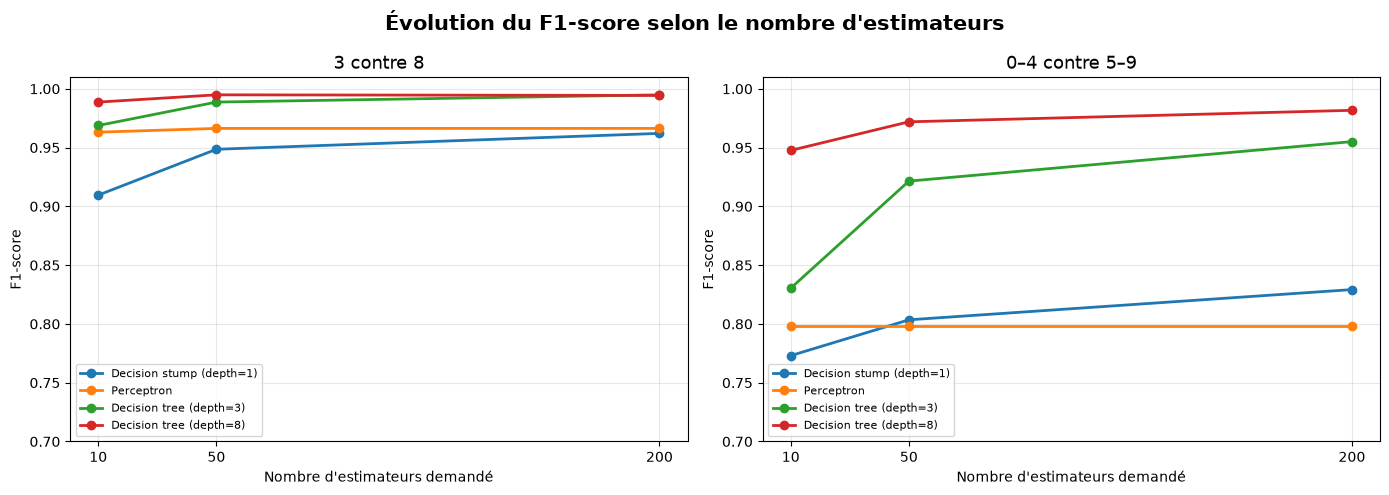

In [11]:

# Évolution du F1-score en fonction du nombre d'estimateurs

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (task_key, task_label) in zip(axes, TASKS.items()):

    subset = results_df[
        (results_df["task"] == task_key)
        & (results_df["status"] == "success")
    ]

    for learner_name in make_weak_learners().keys():

        learner_data = subset[
            subset["weak_learner"] == learner_name
        ].sort_values("n_estimators_requested")

        ax.plot(
            learner_data["n_estimators_requested"],
            learner_data["f1_score"],
            marker="o",
            linewidth=2,
            label=learner_name
        )

    ax.set_title(task_label, fontsize=13)
    ax.set_xlabel("Nombre d'estimateurs demandé")
    ax.set_ylabel("F1-score")
    ax.set_xticks(N_ESTIMATORS_LIST)
    ax.set_ylim(0.7, 1.01)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle(
    "Évolution du F1-score selon le nombre d'estimateurs",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



## 8. Bilan et interprétation

### 8.1 Comparaison des classifieurs faibles

Les résultats montrent que les performances d'AdaBoost dépendent fortement du type de classifieur faible utilisé.

Pour la tâche **3 contre 8**, les meilleurs résultats sont obtenus avec les arbres de décision de profondeur 3 et 8. La configuration avec un arbre de profondeur 3 et 200 estimateurs atteint un F1-score de **0,9949**. La configuration avec un arbre de profondeur 8 et 50 estimateurs obtient exactement le même F1-score. Ces deux configurations sont donc les meilleures de cette tâche selon cet indicateur.

À l'inverse, les decision stumps présentent les performances les plus faibles. Leur F1-score progresse néanmoins de 0,9096 avec 10 estimateurs à 0,9621 avec 200 estimateurs.

Pour la tâche **0–4 contre 5–9**, les arbres de décision donnent également les meilleurs résultats. L'arbre de profondeur 8 avec 200 estimateurs atteint un F1-score de **0,9817**, tandis que l'arbre de profondeur 3 avec 200 estimateurs atteint 0,9551. Les decision stumps obtiennent des performances plus modestes, avec un F1-score maximal de 0,8292.

Le perceptron donne des résultats intermédiaires pour la tâche 3 contre 8 (F1-score de 0,9663 au maximum), mais ses performances sont plus limitées pour la tâche 0–4 contre 5–9 (0,7985).

Ces observations suggèrent que des classifieurs faibles plus complexes, capables de prendre en compte plusieurs variables et leurs interactions, sont mieux adaptés à ces tâches que les decision stumps ou le perceptron.

### 8.2 Influence du nombre d'estimateurs

L'augmentation du nombre d'estimateurs améliore généralement les performances, mais cet effet dépend du classifieur faible et de la tâche considérée.

Pour les decision stumps, le F1-score augmente régulièrement lorsque le nombre d'estimateurs passe de 10 à 200, pour les deux tâches. La même tendance est observée avec les arbres de profondeur 3 et 8, en particulier pour la tâche 0–4 contre 5–9.

Cependant, l'amélioration n'est pas systématique. Pour la tâche 3 contre 8, l'arbre de profondeur 8 atteint déjà un F1-score de 0,9887 avec 10 estimateurs, puis 0,9949 avec 50 estimateurs. Le passage à 200 estimateurs n'apporte pas d'amélioration supplémentaire.

Le perceptron illustre également cette limite : AdaBoost n'entraîne effectivement que 17 estimateurs pour la tâche 3 contre 8 et 6 pour la tâche 0–4 contre 5–9, même lorsque 50 ou 200 estimateurs sont demandés. Les performances restent donc identiques entre ces configurations. Cela montre que le nombre d'estimateurs demandé ne correspond pas nécessairement au nombre effectivement entraîné : l'algorithme peut s'arrêter plus tôt.

### 8.3 Influence de la tâche de classification

La tâche **3 contre 8** est globalement plus facile que la tâche **0–4 contre 5–9**.

Pour la première tâche, plusieurs configurations dépassent 98 % d'accuracy, et les meilleures atteignent environ 99,5 %. En revanche, la classification entre les groupes de chiffres 0–4 et 5–9 est plus difficile pour les modèles les moins complexes. Les decision stumps, par exemple, atteignent seulement 83,35 % d'accuracy avec 200 estimateurs.

Cette différence peut s'expliquer par la nature des problèmes : distinguer deux chiffres précis revient à apprendre des caractéristiques visuelles spécifiques à ces deux classes, tandis que séparer deux groupes de cinq chiffres nécessite de généraliser à une plus grande diversité de formes manuscrites.

Il faut donc davantage de capacité de représentation pour résoudre efficacement la seconde tâche.

### 8.4 Analyse des matrices de confusion

Les matrices de confusion permettent de préciser la nature des erreurs commises par les modèles. Les lignes représentent les vraies classes et les colonnes les classes prédites. La classe 1 correspond toujours au second groupe de chaque tâche.

Pour la tâche **3 contre 8**, la meilleure configuration (arbre de profondeur 3, 200 estimateurs) donne la matrice :

\begin{pmatrix}
1003 & 7\\
3 & 971
\end{pmatrix}

Le modèle commet seulement 10 erreurs sur 1 984 images de test. Sept chiffres 3 sont classés comme des 8 et trois chiffres 8 sont classés comme des 3.

À l'inverse, le decision stump avec 10 estimateurs donne :


\begin{pmatrix}
917 & 93\\
84 & 890
\end{pmatrix}


Il commet 177 erreurs. Les deux types d'erreurs sont plus fréquents, ce qui confirme les limites de ce classifieur pour cette tâche.

Pour la tâche **0–4 contre 5–9**, la meilleure configuration (arbre de profondeur 8, 200 estimateurs) donne :


\begin{pmatrix}
5043 & 96\\
82 & 4779
\end{pmatrix}


Elle commet 178 erreurs sur 10 000 images de test. En revanche, le decision stump avec 10 estimateurs donne :


\begin{pmatrix}
3705 & 1434\\
895 & 3966
\end{pmatrix}

Ce modèle commet 2 329 erreurs. Il confond notamment un nombre important de chiffres du groupe 0–4 avec ceux du groupe 5–9.

### 8.5 Compromis entre performance et temps d'entraînement

Les résultats mettent en évidence un compromis entre la complexité des classifieurs, leurs performances et leur temps d'entraînement.

Les decision stumps sont relativement rapides à entraîner, mais leurs performances restent limitées. Les arbres de profondeur 3 offrent un bon compromis : pour la tâche 3 contre 8, ils atteignent un F1-score de 0,9949 en environ 103 secondes avec 200 estimateurs.

Les arbres de profondeur 8 peuvent obtenir de meilleures performances sur la tâche 0–4 contre 5–9, mais leur coût de calcul est nettement plus élevé. La configuration avec 200 estimateurs nécessite environ **1 145 secondes** (19 minutes), contre environ 381 secondes pour l'arbre de profondeur 3 avec le même nombre d'estimateurs.

Ainsi, la configuration la plus performante n'est pas nécessairement la plus intéressante si l'on tient également compte du temps de calcul.

### 8.6 Conclusion générale

Dans l'ensemble, les expériences montrent que les performances d'AdaBoost dépendent à la fois du classifieur faible, du nombre d'estimateurs et de la difficulté de la tâche.

Les arbres de décision obtiennent les meilleurs résultats, en particulier lorsque leur profondeur et le nombre d'estimateurs sont suffisants. Les decision stumps présentent des performances plus limitées, même si l'augmentation du nombre d'estimateurs améliore progressivement leurs résultats. Le perceptron, quant à lui, atteint rapidement une limite liée à l'arrêt anticipé de l'entraînement.

Enfin, la classification de deux chiffres spécifiques (3 contre 8) est nettement plus facile que la séparation de deux groupes de chiffres (0–4 contre 5–9). Ces résultats illustrent l'importance du choix du classifieur faible et de sa capacité à représenter la complexité des données.